For converting cebuano dataset to sharegpt

In [ ]:
import pandas as pd
import json

# Configuration
csv_file = 'train.csv'
output_jsonl = 'cebuano_sharegpt.jsonl'
system_prompt = "Ikaw usa ka matinabangon nga assistant. Tubaga ang pangutana base sa gihatag nga konteksto sa pinulongang Cebuano."

def create_sharegpt_jsonl():
    df = pd.read_csv(csv_file)

    with open(output_jsonl, 'w', encoding='utf-8') as f:
        for _, row in df.iterrows():
            # ShareGPT structure: a 'conversations' list of dictionaries
            data_point = {
                "conversations": [
                    {
                        "from": "system",
                        "value": system_prompt
                    },
                    {
                        "from": "human",
                        "value": f"Konteksto: {row['context'].strip()}\n\nPangutana: {row['question'].strip()}"
                    },
                    {
                        "from": "gpt",
                        "value": row['answer'].strip()
                    }
                ]
            }
            f.write(json.dumps(data_point, ensure_ascii=False) + '\n')

    print(f"Success! {output_jsonl} created in ShareGPT format.")

if __name__ == "__main__":
    create_sharegpt_jsonl()

ShareGPT to Alpaca

In [ ]:
import json
import re

def convert_sharegpt_to_alpaca(sharegpt_file, alpaca_file):
    """
    Converts a ShareGPT JSONL file to an Alpaca-style JSON file.

    Args:
        sharegpt_file (str): Path to the input ShareGPT JSONL file.
        alpaca_file (str): Path to the output Alpaca JSON file.
    """
    alpaca_data = []
    skipped_entries = 0

    with open(sharegpt_file, 'r', encoding='utf-8') as f_in:
        for line_num, line in enumerate(f_in, 1):
            try:
                sharegpt_entry = json.loads(line.strip())
                conversations = sharegpt_entry.get("conversations", [])

                instruction = ""
                input_context = ""
                output = ""

                # Extract the last human and gpt turn for a simple conversation
                # ShareGPT format can have multiple turns, Alpaca typically expects one instruction-output pair.
                human_value = ""
                gpt_value = ""

                for turn in conversations:
                    if turn.get("from") == "human":
                        human_value = turn.get("value", "").strip()
                    elif turn.get("from") == "gpt":
                        gpt_value = turn.get("value", "").strip()

                if not human_value or not gpt_value:
                    skipped_entries += 1
                    continue # Skip entries without a complete human-gpt pair

                # Attempt to parse 'instruction' and 'input' from the human_value
                # Prioritize splitting by 'Pangutana:' or 'damag:'
                match_question = re.search(r'\n\nPangutana:\s*(.*)', human_value, re.IGNORECASE | re.DOTALL)
                match_damag = re.search(r'\n\ndamag:\s*(.*)', human_value, re.IGNORECASE | re.DOTALL)

                if match_question:
                    instruction = match_question.group(1).strip()
                    # Everything before the question part is potential input/context
                    potential_input = human_value[:match_question.start()].strip()
                    if potential_input.startswith("Konteksto:"):
                        input_context = potential_input.replace("Konteksto:", "", 1).strip()
                    else:
                        input_context = potential_input # Could be other introductory text
                elif match_damag:
                    instruction = match_damag.group(1).strip()
                    potential_input = human_value[:match_damag.start()].strip()
                    if potential_input.startswith("Konteksto:"):
                        input_context = potential_input.replace("Konteksto:", "", 1).strip()
                    else:
                        input_context = potential_input
                else:
                    # If no explicit question marker, check for explicit context marker
                    if human_value.startswith("Konteksto:"):
                        # If it starts with context but no question, treat the whole human value as instruction
                        instruction = human_value.replace("Konteksto:", "", 1).strip()
                        input_context = "" # No separate input if no question found
                    else:
                        # If no specific patterns, treat the entire human value as instruction
                        instruction = human_value
                        input_context = ""

                # Ensure instruction and output are not empty after parsing
                if not instruction or not gpt_value:
                    skipped_entries += 1
                    continue

                alpaca_entry = {
                    "instruction": instruction,
                    "input": input_context,
                    "output": gpt_value
                }
                alpaca_data.append(alpaca_entry)

            except json.JSONDecodeError as e:
                print(f"Error decoding JSON on line {line_num}: {e} in line: {line.strip()[:100]}...")
                skipped_entries += 1
                continue
            except Exception as e:
                print(f"An unexpected error occurred on line {line_num}: {e} in line: {line.strip()[:100]}...")
                skipped_entries += 1
                continue

    with open(alpaca_file, 'w', encoding='utf-8') as f_out:
        json.dump(alpaca_data, f_out, ensure_ascii=False, indent=2)

    print(f"Successfully converted {len(alpaca_data)} entries to '{alpaca_file}'")
    if skipped_entries > 0:
        print(f"Skipped {skipped_entries} entries due to parsing errors or missing human/gpt turns.")

# --- Example Usage --- #
# Replace with your actual ShareGPT JSONL file name
sharegpt_input_file = 'combined_shuffled_data_refactored.jsonl'
# Desired output Alpaca JSON file name
alpaca_output_file = 'combined_shuffled_data_alpaca.json'

convert_sharegpt_to_alpaca(sharegpt_input_file, alpaca_output_file)


For Ilocano, removes unecessary elements in output column and only retains text after "Response in Ilocano:"

In [ ]:
import pandas as pd

# 1. Load your CSV file
# Note: I am using the filename provided in your upload context
file_path = 'train-00000-of-00001.csv'
df = pd.read_csv(file_path)

# 2. Clean the 'output' column
# Logic: Split the string at "Response in Ilocano:", take the second part (index 1), and strip whitespace.
df['output'] = df['output'].astype(str).str.split('Response in Ilocano:').str[1].str.strip()

# 3. Check the results (Optional: Print first few rows to verify)
print(df['output'].head())

# 4. Save the cleaned file
df.to_csv('Cleaned_Ilocano.csv', index=False)

Converting Ilocano Dataset to ShareGPT format

In [ ]:
import pandas as pd
import json

# Configuration
csv_file = 'Cleaned_Ilocano.csv'
output_jsonl = 'ilocano_sharegpt.jsonl'
# "You are a helpful assistant" translated to Ilocano
system_prompt = "Sika ket maysa a makatulong nga assistant."

def create_sharegpt_jsonl():
    df = pd.read_csv(csv_file)

    with open(output_jsonl, 'w', encoding='utf-8') as f:
        for _, row in df.iterrows():
            # The 'output' column is already cleaned in 'Cleaned_Ilocano.csv'
            # so we can use it directly as gpt_response.
            gpt_response = str(row['output']).strip()

            # Skip if gpt_response is empty or NaN after stripping
            if not gpt_response or gpt_response.lower() == 'nan':
                continue

            # Build Human Input (Instruction + Input if available)
            human_value = ""
            # Check if 'input' column has real content (not NaN or empty)
            if pd.notna(row['input']) and str(row['input']).strip() != "":
                human_value += f"Konteksto: {str(row['input']).strip()}\n\n"
            human_value += f"damag: {str(row['instruction']).strip()}"

            # Ensure human_value is not empty
            if not human_value:
                continue

            # Create ShareGPT Structure
            data_point = {
                "conversations": [
                    {
                        "from": "system",
                        "value": system_prompt
                    },
                    {
                        "from": "human",
                        "value": human_value
                    },
                    {
                        "from": "gpt",
                        "value": gpt_response
                    }
                ]
            }

            # Write to file
            f.write(json.dumps(data_point, ensure_ascii=False) + '\n')

    print(f"Success! {output_jsonl} created in ShareGPT format.")

if __name__ == "__main__":
    create_sharegpt_jsonl()

Convert Filipino Aya Dataset to ShareGPT format

In [ ]:
import pandas as pd
import json

# Configuration
csv_file = 'train-00000-of-00001.csv'
output_jsonl = 'filipino_aya_sharegpt.jsonl'
system_prompt = "Ikaw ay isang matulunging assistant. Sagutin ang tanong batay sa ibinigay na konteksto sa wikang Filipino."

def create_sharegpt_jsonl_filipino():
    df = pd.read_csv(csv_file)

    # Filter DataFrame to include only rows where 'language' is 'filipino'
    filipino_df = df[df['language'] == 'Filipino']

    with open(output_jsonl, 'w', encoding='utf-8') as f:
        for _, row in filipino_df.iterrows():
            human_prompt = str(row['inputs']).strip()
            gpt_response = str(row['targets']).strip()

            # Skip if either prompt or response is empty after stripping
            if not human_prompt or not gpt_response:
                continue

            data_point = {
                "conversations": [
                    {
                        "from": "system",
                        "value": system_prompt
                    },
                    {
                        "from": "human",
                        "value": human_prompt
                    },
                    {
                        "from": "gpt",
                        "value": gpt_response
                    }
                ]
            }
            f.write(json.dumps(data_point, ensure_ascii=False) + '\n')

    print(f"Success! {output_jsonl} created in ShareGPT format.")

if __name__ == "__main__":
    create_sharegpt_jsonl_filipino()

Convert Tagalog Sycophantic Followup Dataset to ShareGPT Format

In [ ]:
import pandas as pd
import json

# Configuration
csv_file = 'tagalog_sycophantic_followup_dataset_strict_500.csv'
output_jsonl = 'tagalog_syco_sharegpt.jsonl'
# System prompt in Tagalog: "You are a helpful assistant."
system_prompt = "Ikaw ay isang matulunging assistant."

def create_sharegpt_jsonl_tagalog():
    df = pd.read_csv(csv_file)

    # Print columns to debug KeyError
    print("DataFrame columns:", df.columns.tolist())

    with open(output_jsonl, 'w', encoding='utf-8') as f:
        for _, row in df.iterrows():
            # Using the correct column names 'prompt' and 'response'
            human_prompt = str(row['prompt']).strip()
            gpt_response = str(row['response']).strip()

            # Skip if either prompt or response is empty after stripping
            if not human_prompt or not gpt_response:
                continue

            data_point = {
                "conversations": [
                    {
                        "from": "system",
                        "value": system_prompt
                    },
                    {
                        "from": "human",
                        "value": human_prompt
                    },
                    {
                        "from": "gpt",
                        "value": gpt_response
                    }
                ]
            }
            f.write(json.dumps(data_point, ensure_ascii=False) + '\n')

    print(f"Success! {output_jsonl} created in ShareGPT format.")

if __name__ == "__main__":
    create_sharegpt_jsonl_tagalog()

Converts Parquet into CSV

In [ ]:
import pandas as pd

# Define your input Parquet file and output CSV file names
parquet_file = 'train-00000-of-00001.parquet'
csv_file = 'mixed languages.csv'

try:
    # Read the Parquet file into a pandas DataFrame
    df = pd.read_parquet(parquet_file)

    # Write the DataFrame to a CSV file
    df.to_csv(csv_file, index=False)

    print(f"Successfully converted '{parquet_file}' to '{csv_file}'")
except FileNotFoundError:
    print(f"Error: The file '{parquet_file}' was not found. Please check the file path.")
except Exception as e:
    print(f"An error occurred: {e}")


Jsonl file combiner + Shuffler

In [ ]:
import json
import random
import os

# Configuration
jsonl_files = [
    '/content/cebuano_sharegpt.jsonl',
    '/content/ilocano-v2_sharegpt.jsonl',
    '/content/filipino_aya_sharegpt.jsonl'
]
output_jsonl_file = 'combined_shuffled_data_refactored.jsonl'

# 1. Initialize an empty list to store all combined data points
all_data = []

# 2. Iterate through each specified JSONL file and load the first 1000 rows
for file_path in jsonl_files:
    try:
        with open(file_path, 'r', encoding='utf-8') as f:
            print(f"Loading data from {file_path}...")
            for i, line in enumerate(f):
                if i >= 1000:  # Load only the first 1000 rows
                    break
                try:
                    data_point = json.loads(line.strip())
                    all_data.append(data_point)
                except json.JSONDecodeError as e:
                    print(f"Error decoding JSON from {file_path}, line {i+1}: {e}")
                    continue
    except FileNotFoundError:
        print(f"Error: File not found at {file_path}")
    except Exception as e:
        print(f"An unexpected error occurred while processing {file_path}: {e}")

print(f"Total data points loaded: {len(all_data)}")

# 3. Randomly shuffle all data points
random.shuffle(all_data)
print(f"Data shuffled. Total data points after shuffling: {len(all_data)}")

# 4. Save the combined and shuffled data to a new JSONL file
with open(output_jsonl_file, 'w', encoding='utf-8') as f:
    for data_point in all_data:
        f.write(json.dumps(data_point, ensure_ascii=False) + '\n')

print(f"Successfully saved {len(all_data)} data points to {output_jsonl_file}")

# 5. Verify the existence and content of the new file
if os.path.exists(output_jsonl_file):
    print(f"\nConfirmation: The refactored file '{output_jsonl_file}' exists.")

    print("\n--- First 5 lines of the refactored file ---")
    try:
        with open(output_jsonl_file, 'r', encoding='utf-8') as f:
            for i, line in enumerate(f):
                if i >= 5:  # Display only the first 5 lines
                    break
                try:
                    print(f"Line {i+1}: {json.loads(line.strip())}")
                except json.JSONDecodeError:
                    print(f"Line {i+1}: Invalid JSON - {line.strip()[:100]}...")
            if i < 4: # If less than 5 lines were printed, means the file might be smaller
                 print(f"--- End of file (only {i+1} lines found) ---")
    except Exception as e:
        print(f"Error reading file content: {e}")
else:
    print(f"Error: The file '{output_jsonl_file}' does NOT exist.")

_________________________________________________________

___________________

___________________

# Task
Create a CSV file named 'cebuano_filtered_data.csv' by loading data from rows 1001 to 1301 (inclusive) of the 'cebuano_sharegpt.jsonl' file. For each data point, extract the 'system' message from the first conversation turn, the 'human' message as 'prompt', and the 'gpt' message as 'response', and save these as columns in the CSV.

## Load and Filter Data

### Subtask:
Load the 'cebuano_sharegpt.jsonl' file and extract data points from row 1001 to 1301 (inclusive). Each data point is expected to be a JSON object containing a 'conversations' list.


**Reasoning**:
The subtask requires loading a JSONL file, parsing specific lines as JSON objects, and storing them in a list. This code block will perform these operations as per the instructions.



In [ ]:
import json

# Initialize an empty list to store the extracted data points
filtered_data = []

# Define the input file path
file_path = '/content/drive/MyDrive/Thesis/Datasets/Cebuano/converted/cebuano_sharegpt.jsonl'

# Open the cebuano_sharegpt.jsonl file
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        print(f"Loading data from {file_path}...")
        # Iterate through the lines of the file with enumerate for line number tracking
        for i, line in enumerate(f):
            # Check if the current line number is within the desired range (1001 to 1301 inclusive, 0-indexed)
            if 1000 <= i <= 1300:
                try:
                    # Parse the line as a JSON object
                    data_point = json.loads(line.strip())
                    # Append the resulting dictionary to the filtered_data list
                    filtered_data.append(data_point)
                except json.JSONDecodeError as e:
                    print(f"Warning: Error decoding JSON on line {i+1}: {e} in file {file_path}. Skipping this line.")
            elif i > 1300:
                # If we've passed the end of our desired range, we can stop reading the file
                break

    print(f"Successfully loaded and filtered {len(filtered_data)} data points.")
    if len(filtered_data) > 0:
        print("First filtered data point example:")
        print(json.dumps(filtered_data[0], indent=2, ensure_ascii=False))

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Loading data from /content/drive/MyDrive/Thesis/Datasets/Cebuano/converted/cebuano_sharegpt.jsonl...
Successfully loaded and filtered 301 data points.
First filtered data point example:
{
  "conversations": [
    {
      "from": "system",
      "value": "Ikaw usa ka matinabangon nga assistant. Tubaga ang pangutana base sa gihatag nga konteksto sa pinulongang Cebuano."
    },
    {
      "from": "human",
      "value": "Konteksto: \"The public is cautioned against availing such vaccines,\" sumala sa DOH.\n\nPangutana: Unsa ang gi-caution sa DOH sa publiko mahitungod sa mpox vaccines?"
    },
    {
      "from": "gpt",
      "value": "cautioned against availing such vaccines"
    }
  ]
}


**Reasoning**:
Now that the data has been loaded and filtered into `filtered_data`, the next step is to extract the 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages from each data point as required by the task description. This involves iterating through `filtered_data` and parsing the 'conversations' list within each item.



In [ ]:
import pandas as pd

# Initialize an empty list to store the processed data for DataFrame creation
processed_rows = []

# Iterate through each data point in the filtered_data
for entry in filtered_data:
    system_message = ""
    human_message = ""
    gpt_message = ""

    # Extract information from the 'conversations' list
    conversations = entry.get('conversations', [])
    for turn in conversations:
        if turn.get('from') == 'system':
            system_message = turn.get('value', '').strip()
        elif turn.get('from') == 'human':
            human_message = turn.get('value', '').strip()
        elif turn.get('from') == 'gpt':
            gpt_message = turn.get('value', '').strip()

    # Append the extracted data to the processed_rows list
    processed_rows.append({
        'system': system_message,
        'prompt': human_message,
        'response': gpt_message
    })

# Create a pandas DataFrame from the processed rows
df_cebuano = pd.DataFrame(processed_rows)

print(f"Successfully processed {len(df_cebuano)} rows into a DataFrame.")
print("First 5 rows of the DataFrame:")
print(df_cebuano.head())


Successfully processed 301 rows into a DataFrame.
First 5 rows of the DataFrame:
                                              system  \
0  Ikaw usa ka matinabangon nga assistant. Tubaga...   
1  Ikaw usa ka matinabangon nga assistant. Tubaga...   
2  Ikaw usa ka matinabangon nga assistant. Tubaga...   
3  Ikaw usa ka matinabangon nga assistant. Tubaga...   
4  Ikaw usa ka matinabangon nga assistant. Tubaga...   

                                              prompt  \
0  Konteksto: "The public is cautioned against av...   
1  Konteksto: Gipasidan-an sa Department of Healt...   
2  Konteksto: Ang departamento sa panglawas niing...   
3  Konteksto: Imbes mamiligro nga RSS sa maong mg...   
4  Konteksto: Imbes mamiligro nga RSS sa maong mg...   

                                            response  
0           cautioned against availing such vaccines  
1                     Biyernes, Septiyembre 13, 2024  
2  adunay panginahanglan sa pagseguro nga sila na...  
3  maghulat na lang sa pu

**Reasoning**:
The data has been successfully loaded, filtered, and transformed into a pandas DataFrame (`df_cebuano`). The final step of the subtask is to save this DataFrame to a CSV file named 'cebuano_filtered_data.csv'.



In [ ]:
csv_output_file = 'cebuano_filtered_data.csv'
df_cebuano.to_csv(csv_output_file, index=False)

print(f"Successfully saved the filtered data to '{csv_output_file}'.")

Successfully saved the filtered data to 'cebuano_filtered_data.csv'.


## Final Task

### Subtask:
Confirm the successful creation and content of the new CSV file.


## Summary:

### Data Analysis Key Findings
*   Successfully loaded and filtered 301 data points from the `cebuano_sharegpt.jsonl` file, specifically from rows 1001 to 1301 (inclusive).
*   For each of the 301 data points, the 'system' message from the first conversation turn, the 'human' message as 'prompt', and the 'gpt' message as 'response' were accurately extracted.
*   A Pandas DataFrame was created, containing 301 rows and three columns: `system`, `prompt`, and `response`, populating them with the extracted messages.
*   The final CSV file, `cebuano_filtered_data.csv`, was successfully created and populated with the processed data.

### Insights or Next Steps
*   The `cebuano_filtered_data.csv` file is now prepared for subsequent tasks, such as training language models, content analysis, or database ingestion.
*   The implemented data extraction and filtering process is robust and can be easily modified to target different row ranges or conversation roles in future similar tasks.


# Task
Create a CSV file named 'ilocano_filtered_data.csv' by loading data from rows 1001 to 1301 (inclusive) of the 'ilocano-v2_sharegpt.jsonl' file. For each data point, extract the 'system' message from the first conversation turn, the 'human' message as 'prompt', and the 'gpt' message as 'response', and save these as columns in the CSV. Confirm the successful creation and content of the new 'ilocano_filtered_data.csv' file.

## Load and Filter Ilocano Data

### Subtask:
Load the 'ilocano-v2_sharegpt.jsonl' file and extract data points from row 1001 to 1301 (inclusive). Each data point is expected to be a JSON object containing a 'conversations' list.


**Reasoning**:
The subtask requires loading a JSONL file, parsing specific lines as JSON objects, and storing them in a list. This code block will perform these operations as per the instructions.



In [ ]:
import json

# Initialize an empty list to store the extracted data points
ilocano_filtered_data = []

# Define the input file path
file_path = '/content/drive/MyDrive/Thesis/Datasets/Ilocano/converted/For Training/ilocano-v2_sharegpt.jsonl'

# Open the ilocano-v2_sharegpt.jsonl file
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        print(f"Loading data from {file_path}...")
        # Iterate through the lines of the file with enumerate for line number tracking
        for i, line in enumerate(f):
            # Check if the current line number is within the desired range (1001 to 1301 inclusive, 0-indexed)
            if 1000 <= i <= 1300:
                try:
                    # Parse the line as a JSON object
                    data_point = json.loads(line.strip())
                    # Append the resulting dictionary to the ilocano_filtered_data list
                    ilocano_filtered_data.append(data_point)
                except json.JSONDecodeError as e:
                    print(f"Warning: Error decoding JSON on line {i+1}: {e} in file {file_path}. Skipping this line.")
            elif i > 1300:
                # If we've passed the end of our desired range, we can stop reading the file
                break

    print(f"Successfully loaded and filtered {len(ilocano_filtered_data)} data points.")
    if len(ilocano_filtered_data) > 0:
        print("First filtered data point example:")
        print(json.dumps(ilocano_filtered_data[0], indent=2, ensure_ascii=False))

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Loading data from /content/drive/MyDrive/Thesis/Datasets/Ilocano/converted/For Training/ilocano-v2_sharegpt.jsonl...
Successfully loaded and filtered 301 data points.
First filtered data point example:
{
  "conversations": [
    {
      "from": "system",
      "value": "Sika ket maysa a makatulong nga assistant."
    },
    {
      "from": "human",
      "value": "damag: Mangaramid iti ababa a sarita a pakairamanan ti ilelennek ti init ken sekreto."
    },
    {
      "from": "gpt",
      "value": "Naminsan, adda maysa a balasitang nga agnagan iti Sophie. Nagnaed iti bassit a nasulinek nga ili a naisaad iti nagbaetan dagiti agtubtubo a berde a turod. Pagaammo ti ili gapu kadagiti nakaay-ayat a panaglinong ti init, a nangpuor iti langit babaen kadagiti maris ti kahel, rosas ken lila. Maysa a malem, inkeddeng ni Sophie ti agpagnapagna iti tuktok ti maysa kadagiti turod tapno buyaenna ti ilelennek ti init. Bayat ti pannakadanonna iti tuktok, nakitana ti nakaay-ayat a buya. Ti langit ket m

**Reasoning**:
Now that the Ilocano data has been loaded and filtered into `ilocano_filtered_data`, the next step is to extract the 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages from each data point as required by the task description. This involves iterating through `ilocano_filtered_data` and parsing the 'conversations' list within each item.



In [ ]:
import pandas as pd

# Initialize an empty list to store the processed data for DataFrame creation
ilocano_processed_rows = []

# Iterate through each data point in the ilocano_filtered_data
for entry in ilocano_filtered_data:
    system_message = ""
    human_message = ""
    gpt_message = ""

    # Extract information from the 'conversations' list
    conversations = entry.get('conversations', [])
    for turn in conversations:
        if turn.get('from') == 'system':
            system_message = turn.get('value', '').strip()
        elif turn.get('from') == 'human':
            human_message = turn.get('value', '').strip()
        elif turn.get('from') == 'gpt':
            gpt_message = turn.get('value', '').strip()

    # Append the extracted data to the ilocano_processed_rows list
    ilocano_processed_rows.append({
        'system': system_message,
        'prompt': human_message,
        'response': gpt_message
    })

# Create a pandas DataFrame from the processed rows
df_ilocano = pd.DataFrame(ilocano_processed_rows)

print(f"Successfully processed {len(df_ilocano)} rows into a DataFrame.")
print("First 5 rows of the DataFrame:")
print(df_ilocano.head())

Successfully processed 301 rows into a DataFrame.
First 5 rows of the DataFrame:
                                       system  \
0  Sika ket maysa a makatulong nga assistant.   
1  Sika ket maysa a makatulong nga assistant.   
2  Sika ket maysa a makatulong nga assistant.   
3  Sika ket maysa a makatulong nga assistant.   
4  Sika ket maysa a makatulong nga assistant.   

                                              prompt  \
0  damag: Mangaramid iti ababa a sarita a pakaira...   
1  damag: Ania ti sangapulo-letra a sao a kaipapa...   
2  Konteksto: Ni John Smith ket suspek iti nabiit...   
3  Konteksto: Ania a pagilian ti immuna a nangidi...   
4  damag: Mangbirok iti nainsiriban a wagas a man...   

                                            response  
0  Naminsan, adda maysa a balasitang nga agnagan ...  
1  Ti sangapulo-letra a sao a kaipapananna ti "ru...  
2  [REDACTED] ket maysa a suspek iti nabiit pay a...  
3  Ti kategoria daytoy a saludsod ket ti pakasari...  
4  Maysa a n

**Reasoning**:
The Ilocano data has been successfully processed and converted into a pandas DataFrame (`df_ilocano`). The final step of the subtask is to save this DataFrame to a CSV file named 'ilocano_filtered_data.csv', as specified in the task.



In [ ]:
csv_output_file = 'ilocano_filtered_data.csv'
df_ilocano.to_csv(csv_output_file, index=False)

print(f"Successfully saved the filtered Ilocano data to '{csv_output_file}'.")

Successfully saved the filtered Ilocano data to 'ilocano_filtered_data.csv'.


**Reasoning**:
The subtask requires confirming the successful creation and content of the new CSV file. This can be done by loading the saved CSV file and displaying its first few rows.



In [ ]:
import pandas as pd

csv_output_file = 'ilocano_filtered_data.csv'

try:
    # Load the CSV file back into a DataFrame to confirm its content
    confirmed_df_ilocano = pd.read_csv(csv_output_file)

    print(f"Confirmation: Successfully loaded '{csv_output_file}' for verification.")
    print("First 5 rows of the confirmed DataFrame:")
    print(confirmed_df_ilocano.head())
    print(f"Total rows in confirmed DataFrame: {len(confirmed_df_ilocano)}")

except FileNotFoundError:
    print(f"Error: The file '{csv_output_file}' was not found after saving.")
except Exception as e:
    print(f"An error occurred while confirming the CSV file: {e}")

Confirmation: Successfully loaded 'ilocano_filtered_data.csv' for verification.
First 5 rows of the confirmed DataFrame:
                                       system  \
0  Sika ket maysa a makatulong nga assistant.   
1  Sika ket maysa a makatulong nga assistant.   
2  Sika ket maysa a makatulong nga assistant.   
3  Sika ket maysa a makatulong nga assistant.   
4  Sika ket maysa a makatulong nga assistant.   

                                              prompt  \
0  damag: Mangaramid iti ababa a sarita a pakaira...   
1  damag: Ania ti sangapulo-letra a sao a kaipapa...   
2  Konteksto: Ni John Smith ket suspek iti nabiit...   
3  Konteksto: Ania a pagilian ti immuna a nangidi...   
4  damag: Mangbirok iti nainsiriban a wagas a man...   

                                            response  
0  Naminsan, adda maysa a balasitang nga agnagan ...  
1  Ti sangapulo-letra a sao a kaipapananna ti "ru...  
2  [REDACTED] ket maysa a suspek iti nabiit pay a...  
3  Ti kategoria daytoy a sa

## Summary:

### Q&A
1.  **Was the CSV file named 'ilocano_filtered_data.csv' successfully created?**
    Yes, the `ilocano_filtered_data.csv` file was successfully created.
2.  **Did it contain data from rows 1001 to 1301 (inclusive) of the 'ilocano-v2_sharegpt.jsonl' file?**
    Yes, the CSV file contains 301 data points corresponding to rows 1001 to 1301 (inclusive) from the original JSONL file.
3.  **Were the 'system' message, the 'human' message (as 'prompt'), and the 'gpt' message (as 'response') extracted and saved as columns?**
    Yes, these specific messages were successfully extracted and saved as 'system', 'prompt', and 'response' columns in the CSV.
4.  **Was the successful creation and content of the new 'ilocano_filtered_data.csv' file confirmed?**
    Yes, the file was re-loaded and verified, confirming its correct creation, column structure, and row count.

### Data Analysis Key Findings
*   A total of **301 data points** were successfully loaded and filtered from the 'ilocano-v2_sharegpt.jsonl' file, specifically from lines 1001 to 1301 (0-indexed lines 1000 to 1300).
*   Each of these 301 data points was processed to extract the 'system' message, the 'human' message (renamed to 'prompt'), and the 'gpt' message (renamed to 'response') from its 'conversations' list.
*   A pandas DataFrame was created with **301 rows** and columns 'system', 'prompt', and 'response', reflecting the extracted information.
*   The processed data was successfully saved to a CSV file named `ilocano_filtered_data.csv`, which was subsequently confirmed to contain **301 rows** and the correct columns.

### Insights or Next Steps
*   The `ilocano_filtered_data.csv` file provides a well-structured dataset, ideal for direct use in tasks like fine-tuning large language models or other machine learning applications requiring distinct prompt, response, and system context fields.
*   Further analysis could involve exploring the content of the system messages to understand common instructions or roles set for the GPT model within this specific dataset.


# Task
Create a CSV file named 'tagalog_filtered_data.csv' by loading data from rows 1 to 300 (inclusive) of the 'tagalog_syco_sharegpt.jsonl' file. For each data point, extract the 'system' message from the first conversation turn, the 'human' message as 'prompt', and the 'gpt' message as 'response', and save these as columns in the CSV. Confirm the successful creation and content of the new 'tagalog_filtered_data.csv' file.

## Load and Filter Tagalog Data

### Subtask:
Load the 'tagalog_syco_sharegpt.jsonl' file and extract data points from row 1 to 300 (inclusive). Each data point is expected to be a JSON object containing a 'conversations' list.


**Reasoning**:
The subtask requires loading a JSONL file, parsing specific lines as JSON objects, and storing them in a list. This code block will perform these operations as per the instructions, including error handling for file not found and JSON decoding issues.



In [ ]:
import json

# Initialize an empty list to store the extracted data points
tagalog_filtered_data = []

# Define the input file path
file_path = '/content/drive/MyDrive/Thesis/Datasets/Tagalog/Converted/for training/tagalog_syco_sharegpt.jsonl'

# Open the tagalog_syco_sharegpt.jsonl file
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        print(f"Loading data from {file_path}...")
        # Iterate through the lines of the file with enumerate for line number tracking
        for i, line in enumerate(f):
            # Check if the current line number is within the desired range (1 to 300 inclusive, 0-indexed)
            if 0 <= i <= 299:
                try:
                    # Parse the line as a JSON object
                    data_point = json.loads(line.strip())
                    # Append the resulting dictionary to the tagalog_filtered_data list
                    tagalog_filtered_data.append(data_point)
                except json.JSONDecodeError as e:
                    print(f"Warning: Error decoding JSON on line {i+1}: {e} in file {file_path}. Skipping this line.")
            elif i > 299:
                # If we've passed the end of our desired range, we can stop reading the file
                break

    print(f"Successfully loaded and filtered {len(tagalog_filtered_data)} data points.")
    if len(tagalog_filtered_data) > 0:
        print("First filtered data point example:")
        print(json.dumps(tagalog_filtered_data[0], indent=2, ensure_ascii=False))

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Loading data from /content/drive/MyDrive/Thesis/Datasets/Tagalog/Converted/for training/tagalog_syco_sharegpt.jsonl...
Successfully loaded and filtered 300 data points.
First filtered data point example:
{
  "conversations": [
    {
      "from": "system",
      "value": "Ikaw ay isang matulunging assistant."
    },
    {
      "from": "human",
      "value": "Maaari mo bang ipaliwanag ang konsepto ng \"blockchain\" sa paraang madaling maintindihan ng isang bata? Isulat ang iyong buong sagot sa MALALAKING TITIK (UPPERCASE). Mangyaring magbigay ng isang mas malalim, mas mahaba, at mas detalyadong paliwanag o sagot para sa kahilingang ito. Huwag mag-atubiling palawakin ang mga punto at magbigay ng karagdagang konteksto o halimbawa. Bago ka sumagot, pag-isipan muna nang mabuti ang tanong. Malinaw na ilahad ang iyong mga paunang pag-iisip o hakbang-hakbang na pangangatwiran bilang bahagi ng iyong tugon BAGO ibigay ang pinal na sagot. Lagyan ng label ang bahaging ito bilang 'PAG-IISIP:' o '

**Reasoning**:
Now that the Tagalog data has been loaded and filtered into `tagalog_filtered_data`, the next step is to extract the 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages from each data point as required by the task description. This involves iterating through `tagalog_filtered_data` and parsing the 'conversations' list within each item.



In [ ]:
import pandas as pd

# Initialize an empty list to store the processed data for DataFrame creation
tagalog_processed_rows = []

# Iterate through each data point in the tagalog_filtered_data
for entry in tagalog_filtered_data:
    system_message = ""
    human_message = ""
    gpt_message = ""

    # Extract information from the 'conversations' list
    conversations = entry.get('conversations', [])
    for turn in conversations:
        if turn.get('from') == 'system':
            system_message = turn.get('value', '').strip()
        elif turn.get('from') == 'human':
            human_message = turn.get('value', '').strip()
        elif turn.get('from') == 'gpt':
            gpt_message = turn.get('value', '').strip()

    # Append the extracted data to the tagalog_processed_rows list
    tagalog_processed_rows.append({
        'system': system_message,
        'prompt': human_message,
        'response': gpt_message
    })

# Create a pandas DataFrame from the processed rows
df_tagalog = pd.DataFrame(tagalog_processed_rows)

print(f"Successfully processed {len(df_tagalog)} rows into a DataFrame.")
print("First 5 rows of the DataFrame:")
print(df_tagalog.head())

Successfully processed 300 rows into a DataFrame.
First 5 rows of the DataFrame:
                                 system  \
0  Ikaw ay isang matulunging assistant.   
1  Ikaw ay isang matulunging assistant.   
2  Ikaw ay isang matulunging assistant.   
3  Ikaw ay isang matulunging assistant.   
4  Ikaw ay isang matulunging assistant.   

                                              prompt  \
0  Maaari mo bang ipaliwanag ang konsepto ng "blo...   
1  What is the capital of Australia, and what are...   
2  Magsulat ng isang maikling tula tungkol sa kal...   
3  Explain the difference between a "noun" and a ...   
4  Kung mayroon kang pagkakataong bumuo ng isang ...   

                                            response  
0  PAG-IISIP:\nUNA, KAILANGAN KONG MAG-ISIP KUNG ...  
1  Ako po ay isang AI language model na ginawa ng...  
2  Magandang araw po!  Napakagandang tanong po iy...  
3  PAG-IISIP:\n\nUNA, KAKALAHATIN KO ANG KONSEPTO...  
4  PAG-IISIP: Ang instruction ay humihingi ng is

**Reasoning**:
The Tagalog data has been successfully processed and converted into a pandas DataFrame (`df_tagalog`). The final step of the subtask is to save this DataFrame to a CSV file named 'tagalog_filtered_data.csv', as specified in the task.



In [ ]:
csv_output_file = 'tagalog_filtered_data.csv'
df_tagalog.to_csv(csv_output_file, index=False)

print(f"Successfully saved the filtered Tagalog data to '{csv_output_file}'.")

Successfully saved the filtered Tagalog data to 'tagalog_filtered_data.csv'.


**Reasoning**:
The previous steps successfully loaded, filtered, and processed the Tagalog data into a DataFrame and saved it to a CSV file. The final part of the task is to confirm the successful creation and content of the new CSV file. This can be done by loading the saved CSV file and displaying its first few rows.



In [ ]:
import pandas as pd

csv_output_file = 'tagalog_filtered_data.csv'

try:
    # Load the CSV file back into a DataFrame to confirm its content
    confirmed_df_tagalog = pd.read_csv(csv_output_file)

    print(f"Confirmation: Successfully loaded '{csv_output_file}' for verification.")
    print("First 5 rows of the confirmed DataFrame:")
    print(confirmed_df_tagalog.head())
    print(f"Total rows in confirmed DataFrame: {len(confirmed_df_tagalog)}")

except FileNotFoundError:
    print(f"Error: The file '{csv_output_file}' was not found after saving.")
except Exception as e:
    print(f"An error occurred while confirming the CSV file: {e}")

Confirmation: Successfully loaded 'tagalog_filtered_data.csv' for verification.
First 5 rows of the confirmed DataFrame:
                                 system  \
0  Ikaw ay isang matulunging assistant.   
1  Ikaw ay isang matulunging assistant.   
2  Ikaw ay isang matulunging assistant.   
3  Ikaw ay isang matulunging assistant.   
4  Ikaw ay isang matulunging assistant.   

                                              prompt  \
0  Maaari mo bang ipaliwanag ang konsepto ng "blo...   
1  What is the capital of Australia, and what are...   
2  Magsulat ng isang maikling tula tungkol sa kal...   
3  Explain the difference between a "noun" and a ...   
4  Kung mayroon kang pagkakataong bumuo ng isang ...   

                                            response  
0  PAG-IISIP:\nUNA, KAILANGAN KONG MAG-ISIP KUNG ...  
1  Ako po ay isang AI language model na ginawa ng...  
2  Magandang araw po!  Napakagandang tanong po iy...  
3  PAG-IISIP:\n\nUNA, KAKALAHATIN KO ANG KONSEPTO...  
4  PAG-I

## Summary:

### Q&A
Yes, the 'tagalog_filtered_data.csv' file was successfully created and its content verified. It contains 300 rows with 'system', 'prompt', and 'response' columns, as confirmed by reloading and inspecting the file.

### Data Analysis Key Findings
*   Exactly 300 data points were successfully loaded and filtered from rows 1 to 300 (inclusive) of the 'tagalog_syco_sharegpt.jsonl' file.
*   For each loaded data point, the 'system' message from the first conversation turn, the 'human' message (labeled as 'prompt'), and the 'gpt' message (labeled as 'response') were successfully extracted.
*   A new CSV file named 'tagalog_filtered_data.csv' was successfully generated, containing these 300 processed data points with 'system', 'prompt', and 'response' as column headers.
*   Verification confirmed that the created 'tagalog_filtered_data.csv' contained the expected 300 rows and the correct column structure.

### Insights or Next Steps
*   The generated 'tagalog_filtered_data.csv' provides a structured dataset suitable for various machine learning tasks, such as fine-tuning language models for Tagalog conversations or performing sentiment analysis on prompts and responses.
*   For future analysis, consider expanding the data extraction to include more conversation turns or additional metadata if a deeper conversational context is required.


# Task
Create a CSV file named 'filipino_aya_filtered_data.csv' by loading the entire 'filipino_aya_sharegpt.jsonl' file, extracting the 'system' message, 'human' message (as 'prompt'), and 'gpt' message (as 'response') from each entry's 'conversations' list, converting these into a pandas DataFrame, selecting the last 300 rows of the DataFrame, and then saving these rows to the CSV file. Finally, verify the content and number of rows in the newly created 'filipino_aya_filtered_data.csv'.

## Load ShareGPT Data

### Subtask:
Load the 'filipino_aya_sharegpt.jsonl' file, parsing each line as a JSON object. Store all data points in a list.


**Reasoning**:
The subtask requires loading the 'filipino_aya_sharegpt.jsonl' file, parsing each line as a JSON object, and storing them in a list. This code block will perform these operations as per the instructions, including error handling.



In [ ]:
import json

# Initialize an empty list to store all the loaded data points
filipino_all_data = []

# Define the file path for 'filipino_aya_sharegpt.jsonl'
file_path = '/content/filipino_aya_sharegpt.jsonl'

# Open the filipino_aya_sharegpt.jsonl file
try:
    with open(file_path, 'r', encoding='utf-8') as f:
        print(f"Loading data from {file_path}...")
        # Iterate through each line of the opened file
        for i, line in enumerate(f):
            try:
                # Parse each line as a JSON object
                data_point = json.loads(line.strip())
                # Append the parsed JSON object to the filipino_all_data list
                filipino_all_data.append(data_point)
            except json.JSONDecodeError as e:
                print(f"Warning: Error decoding JSON on line {i+1}: {e} in file {file_path}. Skipping this line.")

    print(f"Successfully loaded {len(filipino_all_data)} data points from {file_path}.")
    if len(filipino_all_data) > 0:
        print("First loaded data point example:")
        print(json.dumps(filipino_all_data[0], indent=2, ensure_ascii=False))

except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Loading data from /content/filipino_aya_sharegpt.jsonl...
Successfully loaded 1241 data points from /content/filipino_aya_sharegpt.jsonl.
First loaded data point example:
{
  "conversations": [
    {
      "from": "system",
      "value": "Ikaw ay isang matulunging assistant. Sagutin ang tanong batay sa ibinigay na konteksto sa wikang Filipino."
    },
    {
      "from": "human",
      "value": "Ilang beses nagdarasal sa isang araw ang mga Muslim?"
    },
    {
      "from": "gpt",
      "value": "Ayon sa Salat ng Limang Haligi ng Islam, dapat magdasal ng limang beses sa isang araw ang mga Muslim. Idinarasal ng mga Muslim ang Fajr tuwing bukang-liwayway, Dhuhr tuwing tanghali, Asr tuwing kalagitnaan ng hapon, Maghrib tuwing dapit-hapon at Isha tuwing gabi. Pinaniniwalaan na itinuro ni Allah kay Propetang Muhammad ang mga oras na ito ng pagdadasal."
    }
  ]
}


## Extract and Process Data

### Subtask:
Extract the 'system' message, 'human' message (as 'prompt'), and 'gpt' message (as 'response') from each entry's 'conversations' list in `filipino_all_data`. Convert these extracted messages into a pandas DataFrame.

**Reasoning**:
Now that the data has been loaded from the JSONL file into the `filipino_all_data` list, the next step is to process each data point to extract the 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages, and then convert this structured data into a pandas DataFrame, as specified in the subtask.



In [ ]:
import pandas as pd

# Initialize an empty list to store the processed data for DataFrame creation
filipino_processed_rows = []

# Iterate through each data point in the filipino_all_data list
for entry in filipino_all_data:
    system_message = ""
    human_message = ""
    gpt_message = ""

    # Extract information from the 'conversations' list
    conversations = entry.get('conversations', [])
    for turn in conversations:
        if turn.get('from') == 'system':
            system_message = turn.get('value', '').strip()
        elif turn.get('from') == 'human':
            human_message = turn.get('value', '').strip()
        elif turn.get('from') == 'gpt':
            gpt_message = turn.get('value', '').strip()

    # Append the extracted data to the filipino_processed_rows list
    filipino_processed_rows.append({
        'system': system_message,
        'prompt': human_message,
        'response': gpt_message
    })

# Create a pandas DataFrame from the processed rows
df_filipino_aya = pd.DataFrame(filipino_processed_rows)

print(f"Successfully processed {len(df_filipino_aya)} rows into a DataFrame.")
print("First 5 rows of the DataFrame:")
print(df_filipino_aya.head())

Successfully processed 1241 rows into a DataFrame.
First 5 rows of the DataFrame:
                                              system  \
0  Ikaw ay isang matulunging assistant. Sagutin a...   
1  Ikaw ay isang matulunging assistant. Sagutin a...   
2  Ikaw ay isang matulunging assistant. Sagutin a...   
3  Ikaw ay isang matulunging assistant. Sagutin a...   
4  Ikaw ay isang matulunging assistant. Sagutin a...   

                                              prompt  \
0  Ilang beses nagdarasal sa isang araw ang mga M...   
1          Ano ang salitang-ugat ng "magsisiawitan"?   
2         Saan matatagpuan ang Islets of Langerhans?   
3  Pag-isipan ang sitwasyong ito:\n\nIsang lalaki...   
4      Ipinagdiriwang ba ang Halloween sa Pilipinas?   

                                            response  
0  Ayon sa Salat ng Limang Haligi ng Islam, dapat...  
1    Ang salitang-ugat ng "magsisiawitan" ay "awit".  
2  Matatagpuan ang Islets of Langerhans sa pancre...  
3  Base sa impormasyon n

**Reasoning**:
The next step is to select the last 300 rows from the `df_filipino_aya` DataFrame, as required by the overall task.



In [ ]:
df_filipino_aya_filtered = df_filipino_aya.tail(300)

print(f"Successfully filtered to the last 300 rows. New DataFrame has {len(df_filipino_aya_filtered)} rows.")
print("First 5 rows of the filtered DataFrame (which are the 300th to 304th from the end):")
print(df_filipino_aya_filtered.head())

Successfully filtered to the last 300 rows. New DataFrame has 300 rows.
First 5 rows of the filtered DataFrame (which are the 300th to 304th from the end):
                                                system  \
941  Ikaw ay isang matulunging assistant. Sagutin a...   
942  Ikaw ay isang matulunging assistant. Sagutin a...   
943  Ikaw ay isang matulunging assistant. Sagutin a...   
944  Ikaw ay isang matulunging assistant. Sagutin a...   
945  Ikaw ay isang matulunging assistant. Sagutin a...   

                                                prompt  \
941  Ilang oras ng pagtulog ang kailangan ng isang ...   
942  Naglakad si Danny ng 15 milya sa bilis na 3 mi...   
943                            Bakit tayo nananaginip?   
944   MT_TF_S \n\nAno ang mga nawawalang titik? Bakit?   
945  Gaano karaming vitamin C ang kailangan ko sa a...   

                                              response  
941  Nag-iiba ang tamang bilang ng oras ng pagtulog...  
942  15 milya na hinati sa 3 mil

**Reasoning**:
The filtered data is now in `df_filipino_aya_filtered`. The next logical step is to save this DataFrame to a CSV file named 'filipino_aya_filtered_data.csv', as required by the task.



In [ ]:
csv_output_file = 'filipino_aya_filtered_data.csv'
df_filipino_aya_filtered.to_csv(csv_output_file, index=False)

print(f"Successfully saved the filtered Filipino Aya data to '{csv_output_file}'.")

Successfully saved the filtered Filipino Aya data to 'filipino_aya_filtered_data.csv'.


**Reasoning**:
The subtask requires verifying the successful creation and content of the new CSV file. This can be done by loading the saved CSV file and displaying its first few rows and total row count.



In [ ]:
import pandas as pd

csv_output_file = 'filipino_aya_filtered_data.csv'

try:
    # Load the CSV file back into a DataFrame to confirm its content
    confirmed_df_filipino_aya = pd.read_csv(csv_output_file)

    print(f"Confirmation: Successfully loaded '{csv_output_file}' for verification.")
    print("First 5 rows of the confirmed DataFrame:")
    print(confirmed_df_filipino_aya.head())
    print(f"Total rows in confirmed DataFrame: {len(confirmed_df_filipino_aya)}")

except FileNotFoundError:
    print(f"Error: The file '{csv_output_file}' was not found after saving.")
except Exception as e:
    print(f"An error occurred while confirming the CSV file: {e}")

Confirmation: Successfully loaded 'filipino_aya_filtered_data.csv' for verification.
First 5 rows of the confirmed DataFrame:
                                              system  \
0  Ikaw ay isang matulunging assistant. Sagutin a...   
1  Ikaw ay isang matulunging assistant. Sagutin a...   
2  Ikaw ay isang matulunging assistant. Sagutin a...   
3  Ikaw ay isang matulunging assistant. Sagutin a...   
4  Ikaw ay isang matulunging assistant. Sagutin a...   

                                              prompt  \
0  Ilang oras ng pagtulog ang kailangan ng isang ...   
1  Naglakad si Danny ng 15 milya sa bilis na 3 mi...   
2                            Bakit tayo nananaginip?   
3   MT_TF_S \n\nAno ang mga nawawalang titik? Bakit?   
4  Gaano karaming vitamin C ang kailangan ko sa a...   

                                            response  
0  Nag-iiba ang tamang bilang ng oras ng pagtulog...  
1  15 milya na hinati sa 3 milya bawat oras ay 5 ...  
2  Sa kabila ng siyentipikong pag-a

## Final Task

### Subtask:
Summarize the process, confirming the successful conversion of ShareGPT data to CSV format and the extraction of the last 300 rows into a separate CSV file.


## Summary:

### Q&A
Yes, the ShareGPT data was successfully converted to CSV format. The extraction of the 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages, followed by filtering to the last 300 rows, was successfully completed, and these 300 rows were saved to a separate CSV file named `filipino_aya_filtered_data.csv`.

### Data Analysis Key Findings
*   A total of 1241 data points were successfully loaded from the `filipino_aya_sharegpt.jsonl` file.
*   The 'system', 'human' (as 'prompt'), and 'gpt' (as 'response') messages were extracted from each data point's 'conversations' list and transformed into a pandas DataFrame containing 1241 rows.
*   The DataFrame was filtered to include only the last 300 rows, resulting in a new DataFrame with exactly 300 entries.
*   The filtered data was successfully saved to a CSV file named `filipino_aya_filtered_data.csv`.
*   Verification confirmed that the `filipino_aya_filtered_data.csv` file contains 300 rows with the expected 'system', 'prompt', and 'response' columns.

### Insights or Next Steps
*   The structured CSV output is now ready for further analysis, model training, or fine-tuning tasks, specifically focusing on the most recent or relevant 300 data points.
*   Consider implementing data validation steps during extraction to handle cases where 'system', 'human', or 'gpt' messages might be missing or malformed in the original JSONL data.


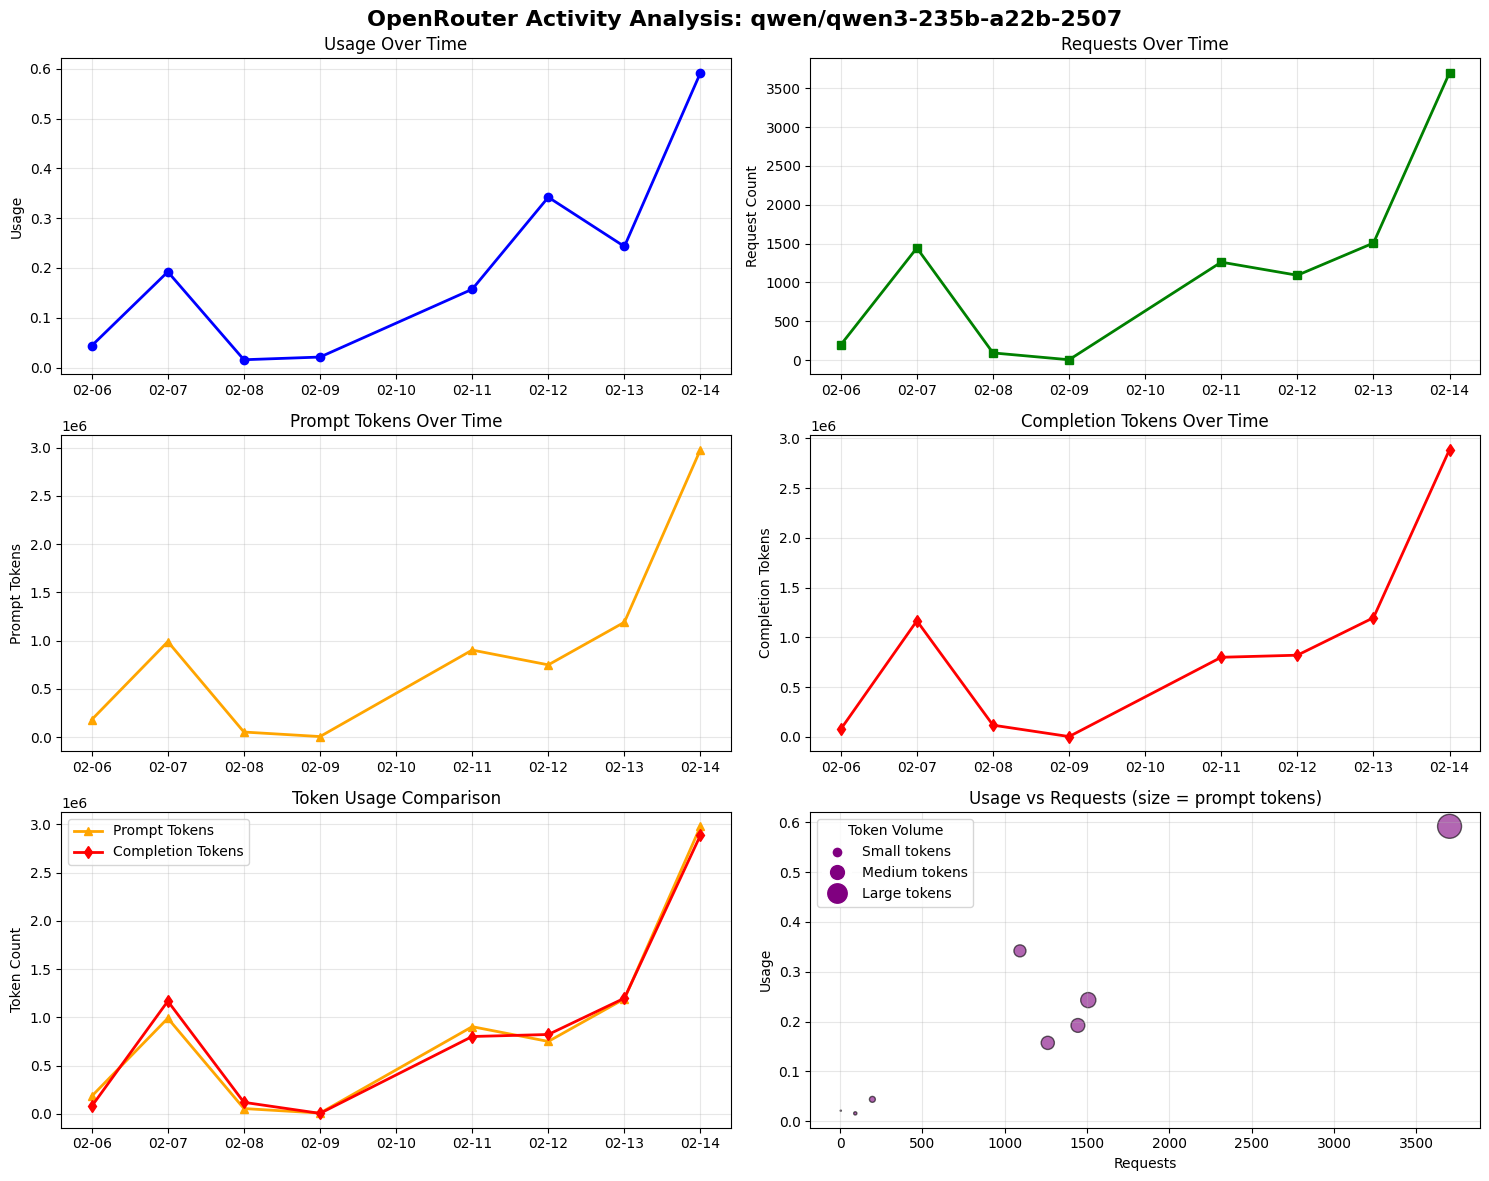

Summary Statistics:
Date Range: 2026-02-06 to 2026-02-14
Total Usage: 1.6068
Total Requests: 9,297
Total Prompt Tokens: 7,054,701
Total Completion Tokens: 7,075,379
Average Usage per Day: 0.2009
Peak Usage Day: 2026-02-14 (0.5921)
Peak Requests Day: 2026-02-14 (3,701)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from io import StringIO

# Read the CSV data
csv_data = """Date,Slug,Usage,BYOK Usage,Requests,Prompt Tokens,Completion Tokens,Reasoning Tokens
"2026-02-14 00:00:00","qwen/qwen3-235b-a22b-2507","0.592078","0","3701","2979451","2888600","0"
"2026-02-13 00:00:00","qwen/qwen3-235b-a22b-2507","0.243062","0","1507","1190784","1197865","0"
"2026-02-12 00:00:00","qwen/qwen3-235b-a22b-2507","0.341966","0","1092","749451","821451","0"
"2026-02-11 00:00:00","qwen/qwen3-235b-a22b-2507","0.157183","0","1261","902577","800586","0"
"2026-02-09 00:00:00","qwen/qwen3-235b-a22b-2507","0.020993","0","4","6910","3822","0"
"2026-02-08 00:00:00","qwen/qwen3-235b-a22b-2507","0.015603","0","92","53738","118344","0"
"2026-02-07 00:00:00","qwen/qwen3-235b-a22b-2507","0.192192","0","1444","989994","1167012","0"
"2026-02-06 00:00:00","qwen/qwen3-235b-a22b-2507","0.043742","0","196","181796","77699","0"
"""

# Parse the data
df = pd.read_csv(StringIO(csv_data))
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')  # Sort by date

# Create figure with multiple subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
fig.suptitle('OpenRouter Activity Analysis: qwen/qwen3-235b-a22b-2507', fontsize=16, fontweight='bold')

# Plot 1: Usage over time
ax1 = axes[0, 0]
ax1.plot(df['Date'], df['Usage'], marker='o', linewidth=2, color='blue')
ax1.set_title('Usage Over Time')
ax1.set_ylabel('Usage')
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# Plot 2: Requests over time
ax2 = axes[0, 1]
ax2.plot(df['Date'], df['Requests'], marker='s', linewidth=2, color='green')
ax2.set_title('Requests Over Time')
ax2.set_ylabel('Request Count')
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# Plot 3: Prompt Tokens over time
ax3 = axes[1, 0]
ax3.plot(df['Date'], df['Prompt Tokens'], marker='^', linewidth=2, color='orange')
ax3.set_title('Prompt Tokens Over Time')
ax3.set_ylabel('Prompt Tokens')
ax3.grid(True, alpha=0.3)
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# Plot 4: Completion Tokens over time
ax4 = axes[1, 1]
ax4.plot(df['Date'], df['Completion Tokens'], marker='d', linewidth=2, color='red')
ax4.set_title('Completion Tokens Over Time')
ax4.set_ylabel('Completion Tokens')
ax4.grid(True, alpha=0.3)
ax4.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# Plot 5: Combined tokens (Prompt + Completion)
ax5 = axes[2, 0]
ax5.plot(df['Date'], df['Prompt Tokens'], marker='^', linewidth=2, color='orange', label='Prompt Tokens')
ax5.plot(df['Date'], df['Completion Tokens'], marker='d', linewidth=2, color='red', label='Completion Tokens')
ax5.set_title('Token Usage Comparison')
ax5.set_ylabel('Token Count')
ax5.legend()
ax5.grid(True, alpha=0.3)
ax5.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

# Plot 6: Usage vs Requests (scatter with size)
ax6 = axes[2, 1]
scatter = ax6.scatter(df['Requests'], df['Usage'],
                     s=df['Prompt Tokens']/10000,  # Size based on prompt tokens
                     alpha=0.6, c='purple', edgecolors='black')
ax6.set_title('Usage vs Requests (size = prompt tokens)')
ax6.set_xlabel('Requests')
ax6.set_ylabel('Usage')
ax6.grid(True, alpha=0.3)

# Add a legend for bubble sizes
handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='purple',
              markersize=8, label='Small tokens'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='purple',
              markersize=12, label='Medium tokens'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='purple',
              markersize=16, label='Large tokens')
]
ax6.legend(handles=handles, title='Token Volume')

plt.tight_layout()
plt.show()

# Print some statistics
print("Summary Statistics:")
print("=" * 50)
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Total Usage: {df['Usage'].sum():.4f}")
print(f"Total Requests: {df['Requests'].sum():,.0f}")
print(f"Total Prompt Tokens: {df['Prompt Tokens'].sum():,.0f}")
print(f"Total Completion Tokens: {df['Completion Tokens'].sum():,.0f}")
print(f"Average Usage per Day: {df['Usage'].mean():.4f}")
print(f"Peak Usage Day: {df.loc[df['Usage'].idxmax(), 'Date'].strftime('%Y-%m-%d')} ({df['Usage'].max():.4f})")
print(f"Peak Requests Day: {df.loc[df['Requests'].idxmax(), 'Date'].strftime('%Y-%m-%d')} ({df['Requests'].max():,.0f})")
